# Reading a MODFLOW 6 DISV vertex grid

**MODFLOW 6** is the USGS modular groundwater-flow simulator. Its **DISV** (discretisation by *vertices*) package describes each layer as an unstructured list of polygon cells built from a shared vertex pool — a *vertex grid*. Polygons may have different numbers of sides, which is what makes DISV more flexible than a classic row/column grid.

`pyramids-mesh` reads the ASCII DISV grid file and hands back a `pyramids.netcdf.ugrid.UgridDataset`; from there the whole pyramids GIS toolbox applies. This sample is FloPy's `test003_gwftri_disv` — 200 cells per layer built from 121 vertices (public-domain USGS data).

## 1. Set up the plotting backend

We render through `cleopatra`/`matplotlib`. To execute identically in CI and interactively we pin the non-interactive **`Agg`** backend *before* importing `pyplot`, and define a tiny `show()` helper that writes the current figure straight into the notebook as a PNG. Call `show()` after every plot.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib; matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight"); plt.close("all"); buf.seek(0)
    display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd

## 3. Locate the example data

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths inside a notebook are written **relative to the notebook itself**. The critical rule for `read_file` is to pass a `pathlib.Path`, never `str(...)`. We read `modflow6/tri_model_cnst.disv`.

In [3]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "modflow6" / "tri_model_cnst.disv"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/modflow6/tri_model_cnst.disv'), True)

## 4. Quickstart: read the file

`UgridDataset.read_file(path, driver=...)` parses the file and returns a `UgridDataset` — the same type pyramids produces from a NetCDF UGRID file. We name the `"modflow6_disv"` driver explicitly; passing the **`Path`** object (not a string) is the supported call.

In [4]:
ds = UgridDataset.read_file(mesh_file, driver="modflow6_disv")
type(ds).__name__

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 200 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


'UgridDataset'

## 5. Explore the dataset

A `UgridDataset` exposes summary properties: `n_node` / `n_face` (mesh size), `crs` / `epsg` (georeferencing if the format recorded any), `bounds` (the `(minx, miny, maxx, maxy)` extent), and `data_variable_names` (attached field variables).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": tuple(round(float(b), 3) for b in ds.bounds),
    "data_variable_names": ds.data_variable_names,
})

n_node                                    121
n_face                                    200
crs                                      None
epsg                                     None
bounds                 (0.0, 0.0, 10.0, 10.0)
data_variable_names                        []
dtype: object

`crs`/`epsg` are `None`: MODFLOW grids store **model coordinates** with no georeferencing — you would assign the real CRS yourself. `data_variable_names` is empty: a grid file is pure topology, with heads and budgets living in separate output files. The extent is the 10x10 model domain.

## 6. Face-degree distribution

`ds.mesh.face_node_connectivity.data` is the `(n_face, k)` table of node indices per face, where `k` is the widest polygon. Cells with fewer nodes than `k` are **padded with `-1` (fill)**. Counting the non-negative entries per row gives each face's number of nodes — its *degree*.

In [6]:
conn = np.asarray(ds.mesh.face_node_connectivity.data)
degree = (conn >= 0).sum(axis=1)
vals, counts = np.unique(degree, return_counts=True)
dist = pd.Series(dict(zip(vals.tolist(), counts.tolist())), name="n_faces")
dist.index.name = "nodes_per_face"
{"degree_distribution": dist.to_dict(), "fill_slots(-1)": int((conn == -1).sum())}

{'degree_distribution': {3: 200}, 'fill_slots(-1)': 0}

Every face here has **3 nodes** and there are **zero `-1` fill slots** — this particular DISV grid is all-triangular, so the connectivity table is dense. The DISV *format* still supports mixed-degree polygons (quads, pentagons, ...) in one grid; when present those shorter rows are `-1`-padded up to the widest cell.

## 7. The underlying geometry

`ds.mesh` is the `Mesh2d` holding the raw arrays: `node_x` / `node_y` (coordinates), the connectivity table, `face_areas` (one area per cell) and `face_centroids` (shape `(2, n_face)`). Everything geometric is derived from the connectivity plus the node coordinates.

In [7]:
mesh = ds.mesh
conn = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
cent = np.asarray(mesh.face_centroids)  # (2, n_face)
{"conn_shape": conn.shape, "n_node": np.asarray(mesh.node_x).shape[0],
 "areas_minmax": (round(float(areas.min()), 4), round(float(areas.max()), 4)),
 "centroids_shape": cent.shape}

{'conn_shape': (200, 3),
 'n_node': 121,
 'areas_minmax': (0.5, 0.5),
 'centroids_shape': (2, 200)}

## 8. Wireframe: `plot_outline()`

The simplest view needs no data — just the mesh edges. `plot_outline()` draws the wireframe through cleopatra; `show()` embeds it. This is the fastest sanity check that a file read in correctly.

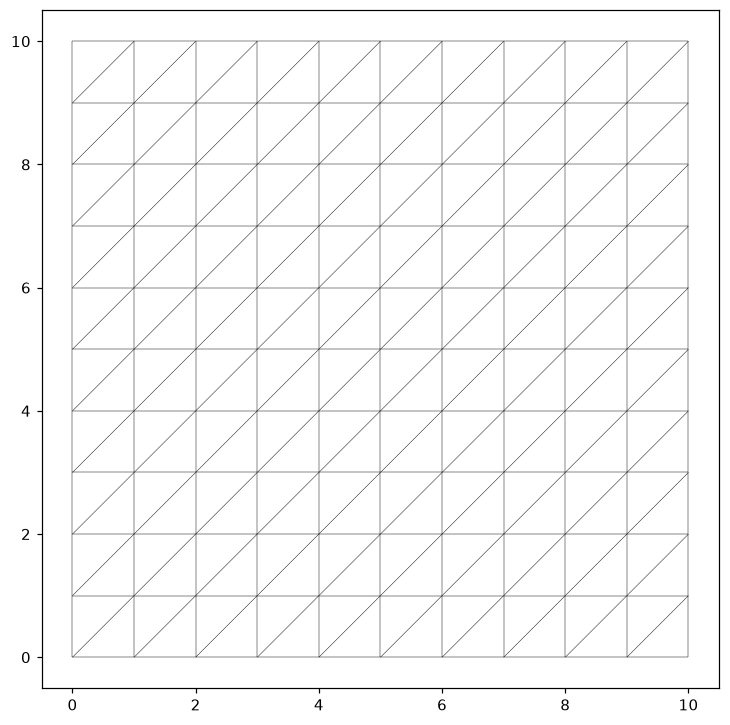

In [8]:
ds.plot_outline()
show()

A regular triangular tessellation of the square domain — exactly the `test003_gwftri` grid. Seeing it draw confirms the vertices and cell connectivity were parsed correctly.

## 9. A data map: attach and colour a field

To draw a *filled* map we need a value per cell. These mesh files carry geometry only, so we compute one — each cell's area — and attach it with `with_variable(..., location="face")`, which returns a **new** dataset (the original `ds` is untouched). Then `plot` colours the mesh by it.

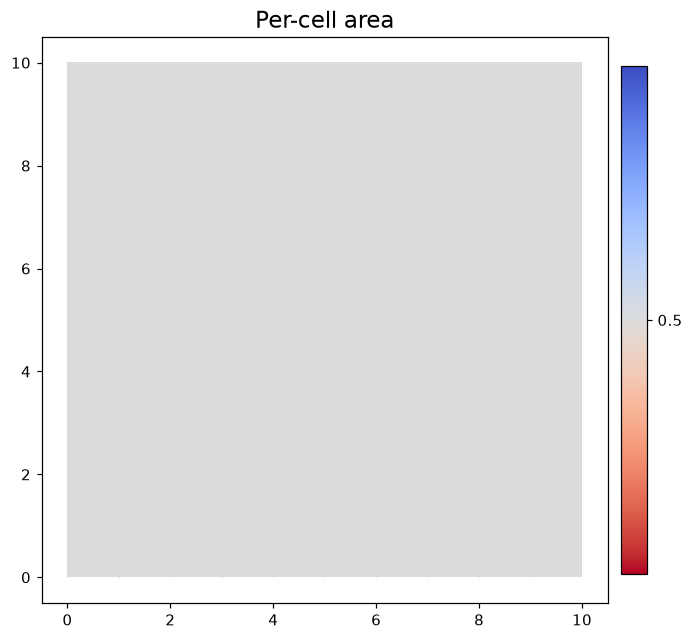

In [9]:
d2 = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="Per-cell area")
show()

Each cell is now shaded by its area. This is the generic pyramids data-map path — any per-cell field (water depth, velocity, head) plots exactly the same way.

### The statistical summary

With a field attached, `.summary()` reports per-variable statistics (count, min, max, mean, std). On the bare `ds` it is an empty frame; on `d2` it has a real row.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
cell_area,200,0.5,0.5,0.5,0.0


## 10. GIS operations, for free

Because the mesh is now a first-class pyramids object, the pyramids GIS layer applies directly — `pyramids-mesh` itself adds none of this. The next cells each run one operation and interpret it.

### Faces as a GeoDataFrame

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((0 9, 1 10, 0 10, 0 9))"
1,"POLYGON ((0 9, 1 9, 1 10, 0 9))"
2,"POLYGON ((1 9, 2 10, 1 10, 1 9))"
3,"POLYGON ((1 9, 2 9, 2 10, 1 9))"
4,"POLYGON ((2 9, 3 10, 2 10, 2 9))"


Plotting that GeoDataFrame draws the mesh footprint as vector polygons (one patch per cell).

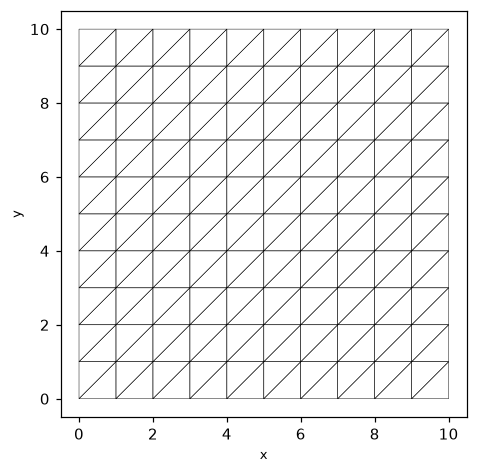

In [12]:
gdf.plot(edgecolor="black", facecolor="none", linewidth=0.3)
show()

### Bounding polygon

`bounding_polygon()` dissolves the cells into a single shapely polygon of the meshed footprint — the gateway to the shapely/geopandas ecosystem for clipping and spatial joins.

In [13]:
poly = ds.bounding_polygon()
poly.geom_type, tuple(round(float(b), 3) for b in poly.bounds)

('Polygon', (0.0, 0.0, 10.0, 10.0))

### Circumcenters

`circumcenters()` returns an `(n_face, 2)` array of per-cell circumcenters — the points a finite-volume scheme places unknowns at. Defined only for **triangular** meshes, which this is.

In [14]:
cc = np.asarray(ds.circumcenters())
cc.shape, np.round(cc[:3], 3)

((200, 2),
 array([[0.5, 9.5],
        [0.5, 9.5],
        [1.5, 9.5]]))

### Exterior edges

`exterior_edges()` returns the node indices of the mesh **boundary** — the edges that belong to exactly one cell. Its length is a quick measure of how much perimeter the mesh has.

In [15]:
edges = np.asarray(ds.exterior_edges())
edges.shape, edges[:6].tolist()

((40,), [1, 2, 6, 10, 14, 18])

40 boundary-edge node entries trace the outer ring of the square domain; interior edges (shared by two triangles) are excluded. For a MODFLOW grid this is the model's active-domain perimeter.

### Cell adjacency and connected components

`sparse_adjacency()` is the cell-to-cell adjacency as a SciPy sparse matrix (`nnz` = twice the number of shared internal edges). `connected_components()` labels which cells are mutually reachable through that adjacency.

In [16]:
adj = ds.sparse_adjacency()
labels = np.asarray(ds.connected_components())
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(labels).size)}

{'adjacency_shape': (200, 200), 'nnz': 560, 'n_components': 1}

A single connected component: every cell is reachable from every other through shared edges, as expected for one contiguous model layer. `nnz` counts the directed shared-edge links between neighbouring cells.

### Subset by a bounding box

`subset_by_bounds(xmin, ymin, xmax, ymax)` keeps only the cells inside a window (note the four positional coordinates, not a tuple). We take the centred 60% window and plot the result — a clean clip that returns a new `UgridDataset`. (`crop(bbox=...)` does the same thing with a tuple argument.)

In [17]:
b = ds.bounds
cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
hx, hy = (b[2] - b[0]) * 0.3, (b[3] - b[1]) * 0.3
sub = ds.subset_by_bounds(cx - hx, cy - hy, cx + hx, cy + hy)
{"full_n_face": ds.n_face, "subset_n_face": sub.n_face}

{'full_n_face': 200, 'subset_n_face': 72}

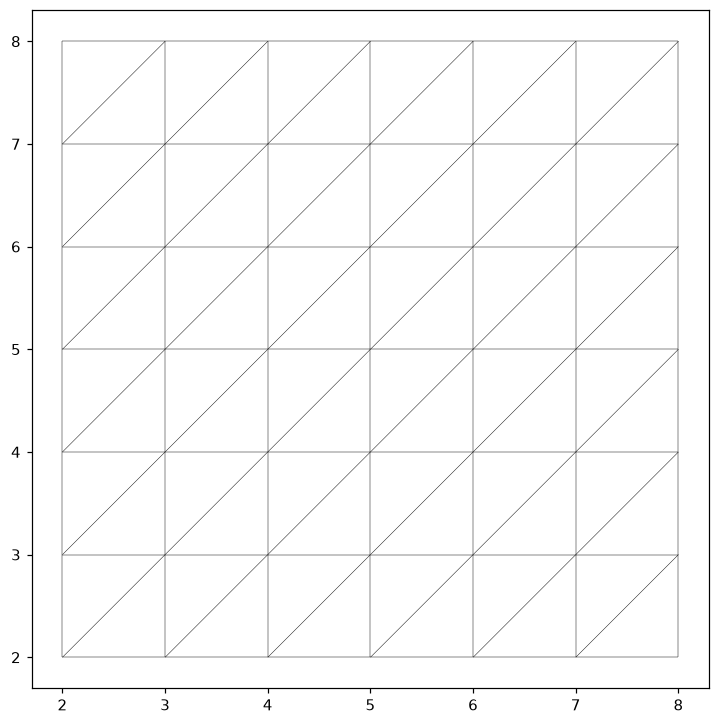

In [18]:
sub.plot_outline()
show()

The window keeps the central block of triangles and drops the rim — a quick way to carve a region of interest out of a MODFLOW domain while staying in the `UgridDataset` world.

### Export: xarray and NetCDF round-trip

`to_xarray()` hands back an `xarray.Dataset` (the UGRID representation), and `to_file(path)` writes a NetCDF UGRID file — the canonical pyramids on-disk form that any UGRID reader can load back.

In [19]:
import tempfile, os
xds = ds.to_xarray()
out = os.path.join(tempfile.gettempdir(), "mesh_roundtrip.nc")
ds.to_file(out)
{"xarray_type": type(xds).__name__, "nc_bytes": os.path.getsize(out)}

{'xarray_type': 'Dataset', 'nc_bytes': 20159}

## 11. CRS-dependent operations — explain and skip

This format records **no CRS** (`crs` / `epsg` were `None` above), so coordinate-aware steps have nothing to work from:

- **`to_crs(...)`** — a reprojection needs a *source* CRS; with `None` there is nothing to reproject from, so we skip it. In practice you would first assign the CRS you know the model used.
- **`rasterize_like(...)` / `regrid(...)`** — these burn the mesh onto, or resample it to, a target **raster grid**. That is the job of the `pyramids-gis` raster layer (you supply a target `Dataset`); it is out of scope for a format-reader tutorial, so we only name it here.

In [20]:
ds.crs  # None -> no reprojection target; to_crs / rasterize_like / regrid skipped

## 12. Takeaway

- **DISV = vertex grid**: polygon cells from a shared vertex pool, read straight into a `UgridDataset`.
- This FloPy sample is all-triangular (degree 3, no `-1` fill), but DISV supports mixed-degree polygons.
- Being triangular, it supports `circumcenters()`; it has no CRS, so reprojection/rasterisation are skipped.
- Once read, explore (`n_node`, `bounds`, `summary()`), plot (`plot_outline`, `plot`) and run GIS (`to_geodataframe`, `bounding_polygon`, `subset_by_bounds`) — all from pyramids, not this package.